# Cvičení 15. 10. 2026 — čištění dat a kvalita anotací
Řešení vychází z `PYR_Data_cleaning_python.ipynb`. Každý oddíl obsahuje postup, spustitelný kód a výsledky. Meteorologická data a anotace zůstávají oddělené. Původní soubory neměníme; pracovní kopie a exporty ukládáme do `vystup`. Neprovádíme imputaci ani detekci odlehlých hodnot.


In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("data")
VYSTUP = Path("vystup")
VYSTUP.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)

In [2]:
import hashlib
otisky = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in DATA.glob('*.csv')}
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)

## 1. Načtení, kontrola schématu a pracovní kopie
Povinné vstupní sloupce jsou identifikátor, čas, teplota a jednotka. Bez nich nelze vytvořit klíč ani teplotu v °C. Stav, vlhkost a čas aktualizace jsou nepovinné: jejich absence je přípustná, ale omezuje provozní výběr nebo určení nejnovější verze. Chybějící vlhkost nijak nedoplňujeme. Řádek zdroje je číslován od 2 včetně hlavičky.

Experiment odstraní vlhkost pouze z pracovní kopie února. Ukazuje běžné spojení i okamžité odmítnutí souboru bez povinného sloupce. Hlavní analýza pak využívá úplné originály.

In [3]:
prejmenovani = {
    'station': 'stanice_id', 'timestamp': 'datum', 'temperature': 'teplota',
    'unit': 'jednotka', 'status': 'stav', 'humidity': 'vlhkost', 'updated': 'aktualizovano'
}
povinne_vstup = ['stanice_id', 'datum', 'teplota', 'jednotka']
nepovinne_vstup = ['stav', 'vlhkost', 'aktualizovano']
def nacti_mesic(cesta, mapa):
    tab = pd.read_csv(cesta, sep=';', dtype='string').rename(columns=mapa)
    chybi = set(povinne_vstup) - set(tab.columns)
    if chybi:
        raise ValueError(f'{Path(cesta).name}: chybí povinné sloupce {sorted(chybi)}')
    for col in nepovinne_vstup:
        if col not in tab:
            tab[col] = pd.Series(pd.NA, index=tab.index, dtype='string')
    return tab.assign(zdroj=Path(cesta).name, radek_zdroje=np.arange(2, len(tab)+2))
pracovni = VYSTUP / 'pracovni_kopie'
pracovni.mkdir(exist_ok=True)
u = pd.read_csv(DATA/'mereni_unor.csv', sep=';', dtype='string')
u.drop(columns='humidity').to_csv(pracovni/'unor_bez_vlhkosti.csv', sep=';', index=False)
experiment = pd.concat([nacti_mesic(DATA/'mereni_leden.csv', {}),
                        nacti_mesic(pracovni/'unor_bez_vlhkosti.csv', prejmenovani)], ignore_index=True)
display(experiment.groupby('zdroj').agg(radku=('datum','size'), zname_vlhkosti=('vlhkost','count')))
u.drop(columns='temperature').to_csv(pracovni/'unor_bez_teploty.csv', sep=';', index=False)
try:
    nacti_mesic(pracovni/'unor_bez_teploty.csv', prejmenovani)
except ValueError as e:
    print('Očekávané přerušení načítání:', e)
else:
    raise AssertionError('Kontrola povinných sloupců nefunguje')
cesty = sorted(DATA.glob('mereni_*.csv'))
assert len(cesty) == 2
raw = pd.concat([nacti_mesic(p, prejmenovani) for p in cesty], ignore_index=True)
raw['vstup_id'] = np.arange(len(raw))
df = raw.copy(deep=True)
display(raw.groupby('zdroj').size().to_frame('pocet_radku'))

Očekávané přerušení načítání: unor_bez_teploty.csv: chybí povinné sloupce ['teplota']


,radku,zname_vlhkosti
zdroj,,
mereni_leden.csv,44,43
unor_bez_vlhkosti.csv,42,0


,pocet_radku
zdroj,
mereni_leden.csv,44
mereni_unor.csv,42


## 2. Normalizace, převody a pravidla vyřazení
Identifikátor musí odpovídat celému řetězci `S[0-9]{2,3}`. Bílé znaky a velikost písmen sjednocujeme před validací. Číselné a časové chyby převádíme na chybějící hodnotu a evidujeme je. Fahrenheit převádíme přesně vztahem `(F − 32) × 5/9`; neznámá jednotka znamená neznámou teplotu v °C.

Pro zachování řádku požadujeme platný identifikátor, datum a teplotu v °C. Neznámý stav ponecháme, avšak nezařadíme jej mezi provozní měření.

In [4]:
df["stanice_id"] = df["stanice_id"].str.strip().str.upper()
df["jednotka"] = df["jednotka"].str.strip().str.upper()
df["stav_puvodni"] = df["stav"]
stav_normalizovany = df["stav"].str.strip().str.lower()
mapa_stavu = {"ok": "ok", "v provozu": "ok", "porucha": "porucha", "údržba": "udrzba"}
df["stav"] = stav_normalizovany.map(mapa_stavu)
neznama_kategorie = stav_normalizovany.notna() & df["stav"].isna()
display(df.loc[neznama_kategorie, ["stav_puvodni", "zdroj"]])
display(df["stav"].value_counts(dropna=False))

,stav_puvodni,zdroj


stav
ok         84
porucha     1
udrzba      1
Name: count, dtype: int64

In [5]:
priklady_id = pd.Series(['S01','S99','S100','S001','S1','S1000','s01','XS01','S01x','S１２'])
test_id = pd.DataFrame({'id': priklady_id, 'platne': priklady_id.str.fullmatch(r'S[0-9]{2,3}', na=False)})
assert test_id.platne.tolist() == [True]*4 + [False]*6
display(test_id)
format_id_ok = df.stanice_id.str.fullmatch(r'S[0-9]{2,3}', na=False)
display(df.loc[~format_id_ok])

,id,platne
0,S01,True
1,S99,True
2,S100,True
3,S001,True
4,S1,False
5,S1000,False
6,s01,False
7,XS01,False
8,S01x,False
9,S１２,False


,stanice_id,datum,teplota,jednotka,stav,vlhkost,aktualizovano,zdroj,radek_zdroje,vstup_id,stav_puvodni
52,<NA>,2026-02-02 08:00,"8,4",C,ok,46,2026-02-02 18:00,mereni_unor.csv,10,52,OK


In [6]:
chyby_prevodu = []
for sloupec in ["teplota", "vlhkost"]:
    puvodni = df[sloupec].copy()
    df[sloupec] = pd.to_numeric(puvodni.str.replace(",", ".", regex=False), errors="coerce")
    chyba = puvodni.notna() & df[sloupec].isna()
    chyby_prevodu.append(df.loc[chyba, ["stanice_id", "zdroj"]].assign(
        sloupec=sloupec, puvodni_hodnota=puvodni.loc[chyba]))
for sloupec in ["datum", "aktualizovano"]:
    puvodni = df[sloupec].copy()
    df[sloupec] = pd.to_datetime(puvodni, format="%Y-%m-%d %H:%M", errors="coerce")
    chyba = puvodni.notna() & df[sloupec].isna()
    chyby_prevodu.append(df.loc[chyba, ["stanice_id", "zdroj"]].assign(
        sloupec=sloupec, puvodni_hodnota=puvodni.loc[chyba]))
chyby_prevodu = pd.concat(chyby_prevodu, ignore_index=True)
display(chyby_prevodu)

# Fahrenheit -> Celsius. Původní hodnota a jednotka zůstávají dohledatelné v raw.
df["teplota_C"] = df["teplota"].where(df["jednotka"].eq("C"))
je_f = df["jednotka"].eq("F")
df.loc[je_f, "teplota_C"] = (df.loc[je_f, "teplota"] - 32) * 5 / 9
display(df.loc[je_f, ["teplota", "jednotka", "teplota_C"]])

,stanice_id,zdroj,sloupec,puvodni_hodnota
0,S02,mereni_leden.csv,teplota,chyba
1,S03,mereni_unor.csv,vlhkost,nezjištěno
2,S03,mereni_leden.csv,datum,neznámé


,teplota,jednotka,teplota_C
44,46.8,F,8.222222


In [7]:
# Obě masky nad naprosto stejnou tabulkou po převodech, před jakýmkoli mazáním.
povinne = ['stanice_id','datum','teplota_C']
navic_odstranene = df.loc[df.isna().any(axis=1) & df[povinne].notna().all(axis=1)].copy()
navic_odstranene['chybejici_nepovinne'] = navic_odstranene.apply(
    lambda r: ', '.join(c for c in df.columns if c not in povinne and pd.isna(r[c])), axis=1)
display(navic_odstranene)

,stanice_id,datum,teplota,jednotka,stav,vlhkost,aktualizovano,zdroj,radek_zdroje,vstup_id,stav_puvodni,teplota_C,chybejici_nepovinne
3,S02,2026-01-01 16:00:00,2.4,C,ok,<NA>,2026-01-01 18:00:00,mereni_leden.csv,5,3,OK,2.4,vlhkost
54,S03,2026-02-02 08:00:00,8.3,C,ok,<NA>,2026-02-02 18:00:00,mereni_unor.csv,12,54,OK,8.3,vlhkost


In [8]:
duvody = pd.Series('', index=df.index, dtype='string')
for col in povinne:
    mask = df[col].isna()
    duvody.loc[mask] += f'chybí/neplatné {col}; '
duvody.loc[~format_id_ok] += 'neplatný formát stanice_id; '
vyrazeno_na = df.loc[duvody.ne('')].copy()
vyrazeno_na['duvod'] = duvody.loc[duvody.ne('')]
df = df.loc[duvody.eq('')].copy()
display(vyrazeno_na)

,stanice_id,datum,teplota,jednotka,stav,vlhkost,aktualizovano,zdroj,radek_zdroje,vstup_id,stav_puvodni,teplota_C,duvod
1,S01,2026-01-01 16:00:00,<NA>,C,ok,61,2026-01-01 18:00:00,mereni_leden.csv,3,1,OK,<NA>,chybí/neplatné teplota_C;
9,S02,2026-01-02 16:00:00,<NA>,C,ok,81,2026-01-02 18:00:00,mereni_leden.csv,11,9,OK,<NA>,chybí/neplatné teplota_C;
11,S03,NaT,3.1,C,ok,67,2026-01-02 18:00:00,mereni_leden.csv,13,11,OK,3.1,chybí/neplatné datum;
52,<NA>,2026-02-02 08:00:00,8.4,C,ok,46,2026-02-02 18:00:00,mereni_unor.csv,10,52,OK,8.4,chybí/neplatné stanice_id; neplatný formát stanice_id;


## 3. Duplicity a nejnovější oprava
`keep="first"` závisí na pořadí. Po vzestupném seřazení vybere nejstarší aktualizaci; pro nejnovější verzi proto třídíme sestupně. Chybějící aktualizace řadíme nakonec, při shodném čase ponecháme první vstupní řádek. Následující srovnání zobrazuje všechny konfliktní klíče včetně opraveného měření.

In [9]:
klic = ['stanice_id','datum']
konflikt = df.loc[df.duplicated(klic, keep=False)].copy()
varianty = []
for varianta, tab in {
    'původní pořadí': df,
    'čas vzestupně + first': df.sort_values('aktualizovano', kind='stable', na_position='last'),
    'čas sestupně + first (volíme)': df.sort_values('aktualizovano', ascending=False, kind='stable', na_position='last')
}.items():
    vyber = tab.drop_duplicates(klic, keep='first')
    varianty.append(vyber.merge(konflikt[klic].drop_duplicates(), on=klic).assign(varianta=varianta))
display(pd.concat(varianty)[klic+['teplota_C','aktualizovano','vstup_id','varianta']])
serazeno = df.sort_values('aktualizovano', ascending=False, kind='stable', na_position='last')
stare_verze = serazeno.loc[serazeno.duplicated(klic, keep='first')].copy()
stare_verze['duvod'] = 'duplicitní klíč: ponechána nejnovější dostupná aktualizace, při shodě první vstup'
df = serazeno.drop_duplicates(klic, keep='first').copy()
assert not df.duplicated(klic).any()

,stanice_id,datum,teplota_C,aktualizovano,vstup_id,varianta
0,S01,2026-01-01 08:00:00,5.6,2026-01-01 18:00:00,0,původní pořadí
1,S02,2026-01-01 08:00:00,6.9,2026-01-01 18:00:00,2,původní pořadí
0,S01,2026-01-01 08:00:00,5.6,2026-01-01 18:00:00,0,čas vzestupně + first
1,S02,2026-01-01 08:00:00,6.9,2026-01-01 18:00:00,2,čas vzestupně + first
0,S02,2026-01-01 08:00:00,7.5,2026-01-08 10:00:00,43,čas sestupně + first (volíme)
1,S01,2026-01-01 08:00:00,5.6,2026-01-01 18:00:00,0,čas sestupně + first (volíme)


## 4. Spojování a kontrola číselníku
`many_to_one` zabraňuje násobení měření duplicitním číselníkem. Left zachová měření, inner jen spárovaná měření a outer také stanice bez měření. Nespárované identifikátory exportujeme odděleně. Stanici S777 přidáváme výhradně do pracovní kopie číselníku.

In [10]:
stanice = pd.read_csv(DATA / "stanice.csv", dtype="string")
chybny = pd.read_csv(DATA / "stanice_chybny_ciselnik.csv", dtype="string")
bez_kontroly = df.merge(chybny, on="stanice_id", how="left")
print("Řádky před spojením / s chybným číselníkem:", len(df), len(bez_kontroly))
print("Součet teplot před / po:", df["teplota_C"].sum(), bez_kontroly["teplota_C"].sum())
# Součet zde slouží jen jako kontrolní veličina, ne jako meteorologická statistika.
try:
    df.merge(chybny, on="stanice_id", how="left", validate="many_to_one")
except pd.errors.MergeError as chyba:
    print("Očekávaná chyba kontroly:", chyba)

spojeno = df.merge(stanice, on="stanice_id", how="left",
                  validate="many_to_one", indicator=True)
nesparovane = spojeno.loc[spojeno["_merge"].eq("left_only")].copy()
display(nesparovane[klic + ["teplota_C", "zdroj"]])
# Cílem další analýzy je přehled známých stanic. Neznámá ID ponecháme v reportu.
mereni = spojeno.loc[spojeno["_merge"].eq("both")].drop(columns="_merge").copy()

Řádky před spojením / s chybným číselníkem: 80 106
Součet teplot před / po: 482.32222222222225 642.3444444444444
Očekávaná chyba kontroly: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 stanice_id
       S01 ...


,stanice_id,datum,teplota_C,zdroj
37,S99,2026-02-01 08:00:00,6.3,mereni_unor.csv


In [11]:
stanice_test = pd.concat([stanice, pd.DataFrame([{'stanice_id':'S777','nazev':'Testovací stanice bez měření','oblast':'Test'}])], ignore_index=True)
spojeni = {}
for jak in ['left','inner','outer']:
    tab = df.merge(stanice_test, on='stanice_id', how=jak, validate='many_to_one', indicator=True)
    spojeni[jak] = tab
    print(jak, 'řádků:', len(tab), 'ID:', sorted(tab.stanice_id.dropna().unique()))
display(pd.DataFrame({j:t['_merge'].value_counts() for j,t in spojeni.items()}).fillna(0))
bez_mereni = spojeni['outer'].loc[spojeni['outer']['_merge'].eq('right_only'), ['stanice_id','nazev']]
display(bez_mereni)
nesparovana_id = nesparovane[['stanice_id']].drop_duplicates().sort_values('stanice_id')
nesparovana_id.to_csv(VYSTUP/'nesparovane_stanice.csv', index=False)
display(nesparovana_id)

left řádků: 80 ID: ['S01', 'S02', 'S03', 'S99']
inner řádků: 79 ID: ['S01', 'S02', 'S03']
outer řádků: 81 ID: ['S01', 'S02', 'S03', 'S777', 'S99']


,left,inner,outer
_merge,,,
both,79,79,79
left_only,1,0,1
right_only,0,0,1


,stanice_id,nazev
79,S777,Testovací stanice bez měření


,stanice_id
37,S99


## 5. Denní a měsíční statistiky
Podíl `ok` má ve jmenovateli všechny vyčištěné záznamy známých stanic, tedy také poruchy, údržbu a neznámé stavy. Denní počty nejprve vypočteme pro všechny známé stanice, zatímco průměry teplot počítáme jen z provozních měření.

Přímý měsíční průměr váží každý den počtem provozních měření. Průměr denních průměrů dává každému dni stejnou váhu. Při nestejném počtu měření se výsledky mohou lišit; dny bez provozního měření se do průměru denních průměrů nezapočtou.

In [12]:
mereni["den"] = mereni["datum"].dt.normalize()
mereni["mesic"] = mereni["datum"].dt.to_period("M").astype("string")
provozni = mereni.loc[mereni["stav"].eq("ok")].copy()
prehled = provozni.groupby(["stanice_id", "nazev", "mesic"], as_index=False).agg(
    pocet_mereni=("teplota_C", "size"),
    prumer_teploty=("teplota_C", "mean"),
    minimum=("teplota_C", "min"), maximum=("teplota_C", "max"),
    pocet_vlhkosti=("vlhkost", "count"), prumer_vlhkosti=("vlhkost", "mean")
)
display(prehled)
assert prehled["pocet_mereni"].sum() == len(provozni)

,stanice_id,nazev,mesic,pocet_mereni,prumer_teploty,minimum,maximum,pocet_vlhkosti,prumer_vlhkosti
0,S01,Ústí centrum,2026-01,11,4.981818,3.3,6.8,11,63.545455
1,S01,Ústí centrum,2026-02,13,7.340171,5.2,9.6,13,55.769231
2,S02,Děčín centrum,2026-01,14,5.892857,2.4,9.3,13,65.153846
3,S02,Děčín centrum,2026-02,12,6.083333,4.1,8.7,12,64.416667
4,S03,Teplice centrum,2026-01,13,4.692308,1.6,7.3,13,63.846154
5,S03,Teplice centrum,2026-02,14,7.107143,4.4,9.7,13,64.538462


Příklad: přímý průměr 7.5 průměr dnů 5.0


vsechny  pocet_ok  podil_ok
stanice_id mesic                               
S01        2026-01       12        11  0.916667
           2026-02       14        13  0.928571
S02        2026-01       14        14  1.000000
           2026-02       12        12  1.000000
S03        2026-01       13        13  1.000000
           2026-02       14        14  1.000000

pocet_teplot  pocet_vlhkosti
stanice_id den                                     
S01        2026-01-01             1               1
           2026-01-02             1               1
           2026-01-03             2               2
           2026-01-04             2               2
           2026-01-05             2               2
...                             ...             ...
S03        2026-02-03             2               2
           2026-02-04             2               2
           2026-02-05             2               2
           2026-02-06             2               2
           2026-02-07             2               2

[42 rows x 2 columns]

,stanice_id,datum,teplota_C,denni_prumer
0,S01,2026-02-07 08:00:00,7.0,6.75
1,S01,2026-02-07 16:00:00,6.5,6.75
2,S02,2026-02-07 08:00:00,5.0,6.2
3,S02,2026-02-07 16:00:00,7.4,6.2
4,S03,2026-02-07 08:00:00,9.7,8.7
5,S03,2026-02-07 16:00:00,7.7,8.7
6,S01,2026-02-06 08:00:00,8.7,8.3
7,S01,2026-02-06 16:00:00,7.9,8.3
8,S02,2026-02-06 08:00:00,7.5,5.8
9,S02,2026-02-06 16:00:00,4.1,5.8


prumer_teploty  prumer_dnu  min_n  max_n    rozdil
stanice_id mesic                                                      
S01        2026-01        4.981818    5.035714      1      2 -0.053896
           2026-02        7.340171    7.337302      1      2  0.002869
S02        2026-01        5.892857    5.892857      2      2       0.0
           2026-02        6.083333    6.357143      1      2  -0.27381
S03        2026-01        4.692308    4.592857      1      2  0.099451
           2026-02        7.107143    7.107143      2      2       0.0

mesic,2026-01,2026-02
stanice_id,,
S01,4.981818,7.340171
S02,5.892857,6.083333
S03,4.692308,7.107143


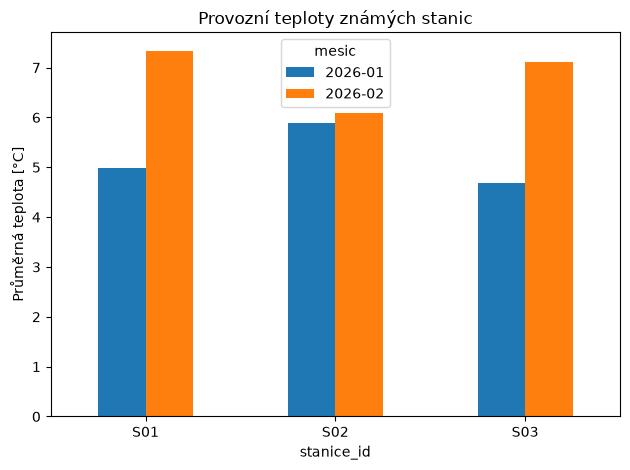

In [13]:
podily = mereni.assign(je_ok=mereni.stav.eq('ok').fillna(False)).groupby(['stanice_id','mesic']).agg(
    vsechny=('stav','size'), pocet_ok=('je_ok','sum'), podil_ok=('je_ok','mean'))
denni = mereni.groupby(['stanice_id','den']).agg(pocet_teplot=('teplota_C','count'), pocet_vlhkosti=('vlhkost','count'))
provozni['denni_prumer'] = provozni.groupby(['stanice_id','den']).teplota_C.transform('mean')
denni_provoz = provozni.groupby(['stanice_id','mesic','den'], as_index=False).agg(prumer=('teplota_C','mean'), n=('teplota_C','size'))
mesic_denni = denni_provoz.groupby(['stanice_id','mesic']).agg(prumer_dnu=('prumer','mean'), min_n=('n','min'), max_n=('n','max'))
porovnani = prehled.set_index(['stanice_id','mesic'])[['prumer_teploty']].join(mesic_denni)
porovnani['rozdil'] = porovnani.prumer_teploty - porovnani.prumer_dnu
siroka_teplota = prehled.pivot(index='stanice_id', columns='mesic', values='prumer_teploty')
display(podily, denni, provozni[klic+['teplota_C','denni_prumer']].head(12), porovnani, siroka_teplota)
# Kontrolovaný příklad: dva dny s 1 a 3 měřeními.
ukazka = pd.DataFrame({'den':[1,2,2,2], 'teplota':[0.,10.,10.,10.]})
print('Příklad: přímý průměr', ukazka.teplota.mean(), 'průměr dnů', ukazka.groupby('den').teplota.mean().mean())
ax = siroka_teplota.plot.bar(ylabel='Průměrná teplota [°C]', title='Provozní teploty známých stanic')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 6. Audit meteorologických úprav
Audit změn je veden po vstupním řádku a sloupci, vždy s původní i výslednou hodnotou. Vyřazení chyb, duplicit a oddělení neznámých stanic mají vlastní soubory. Typový převod bez změny textového zápisu není samostatná věcná oprava; vytvoření teploty v °C evidujeme jako odvození.

In [14]:
# Srovnáme i vyřazené řádky: převedená tabulka vznikne z raw stejným postupem.
# Předchozí tabulky stále obsahují všechny vstup_id v součtu těchto tří skupin.
prevedene = pd.concat([df, stare_verze, vyrazeno_na], ignore_index=True).set_index('vstup_id')
zmeny=[]
for r in raw.itertuples(index=False):
    po = prevedene.loc[r.vstup_id]
    for col in ['stanice_id','jednotka','stav','teplota','vlhkost','datum','aktualizovano']:
        a,b=getattr(r,col),po[col]
        if (pd.isna(a) and pd.isna(b)) or (not pd.isna(a) and not pd.isna(b) and str(a)==str(b)):
            continue
        zmeny.append({'vstup_id':r.vstup_id,'zdroj':r.zdroj,'radek_zdroje':r.radek_zdroje,
                       'sloupec':col,'pred':a,'po':b,'duvod':'normalizace / typový převod; neplatné na NA'})
    zmeny.append({'vstup_id':r.vstup_id,'zdroj':r.zdroj,'radek_zdroje':r.radek_zdroje,
                   'sloupec':'teplota_C','pred':r.teplota,'po':po.teplota_C,'duvod':f'převod z jednotky {r.jednotka} na °C'})
audit_zmen = pd.DataFrame(zmeny)
assert len(raw) == len(vyrazeno_na)+len(stare_verze)+len(df)
audit = pd.DataFrame({'krok':['vstup','neplatné/chybějící povinné','duplicitní klíče','neznámé stanice','známé stanice','provozní'],
                      'pocet':[len(raw),len(vyrazeno_na),len(stare_verze),len(nesparovane),len(mereni),len(provozni)]})
display(audit, audit_zmen.head(15))
for name,tab in {'audit':audit,'audit_zmen':audit_zmen,'chyby_prevodu':chyby_prevodu,'vyrazene_chybejici':vyrazeno_na,
                 'stare_verze':stare_verze,'nesparovane':nesparovane,'mereni_cista':mereni,'prehled_mesicni':prehled,
                 'denni_souhrn':denni.reset_index(),'podily_ok':podily.reset_index(),'porovnani_prumeru':porovnani.reset_index()}.items():
    tab.to_csv(VYSTUP/f'{name}.csv', index=False)
siroka_teplota.to_csv(VYSTUP/'skutecne_teploty_siroka.csv')

,krok,pocet
0,vstup,86
1,neplatné/chybějící povinné,4
2,duplicitní klíče,2
3,neznámé stanice,1
4,známé stanice,79
5,provozní,77


,vstup_id,zdroj,radek_zdroje,sloupec,pred,po,duvod
0,0,mereni_leden.csv,2,jednotka,C,C,normalizace / typový převod; neplatné na NA
1,0,mereni_leden.csv,2,stav,OK,ok,normalizace / typový převod; neplatné na NA
2,0,mereni_leden.csv,2,teplota,"5,6",5.6,normalizace / typový převod; neplatné na NA
3,0,mereni_leden.csv,2,datum,2026-01-01 08:00,2026-01-01 08:00:00,normalizace / typový převod; neplatné na NA
4,0,mereni_leden.csv,2,aktualizovano,2026-01-01 18:00,2026-01-01 18:00:00,normalizace / typový převod; neplatné na NA
5,0,mereni_leden.csv,2,teplota_C,"5,6",5.6,převod z jednotky C na °C
6,1,mereni_leden.csv,3,jednotka,C,C,normalizace / typový převod; neplatné na NA
7,1,mereni_leden.csv,3,stav,OK,ok,normalizace / typový převod; neplatné na NA
8,1,mereni_leden.csv,3,datum,2026-01-01 16:00,2026-01-01 16:00:00,normalizace / typový převod; neplatné na NA
9,1,mereni_leden.csv,3,aktualizovano,2026-01-01 18:00,2026-01-01 18:00:00,normalizace / typový převod; neplatné na NA


## 7. Názvy: podobnost, nejednoznačnost a ověření prahů
Používáme normalizaci diakritiky, velikosti a mezer a Levenshteinovo skóre `100 × (1 − vzdálenost / maximální délka)`. Jedna chyba více poškodí krátký název. Přesná shoda je přijatelná jen při jedinečném normalizovaném názvu. Ostatní návrhy nad prahem skóre i odstupu zařazujeme k ruční kontrole, zbývající nemají dostatečnou shodu. Ani silný návrh automaticky nepřepisuje zdrojový název.

In [15]:
import unicodedata

def normalizuj_nazev(text):
    # Normalizace pro porovnání; původní názvy pro zobrazení zachováme.
    text = unicodedata.normalize("NFKD", str(text).strip().casefold())
    text = "".join(znak for znak in text if not unicodedata.combining(znak))
    return " ".join(text.split())

def levenshtein(a, b):
    predchozi = list(range(len(b) + 1))
    for i, znak_a in enumerate(a, start=1):
        aktualni = [i]
        for j, znak_b in enumerate(b, start=1):
            aktualni.append(min(aktualni[-1] + 1, predchozi[j] + 1,
                                 predchozi[j-1] + (znak_a != znak_b)))
        predchozi = aktualni
    return predchozi[-1]

def podobnost(a, b):
    delka = max(len(a), len(b))
    return 100.0 if delka == 0 else 100 * (1 - levenshtein(a, b) / delka)

reference_nazvu = pd.read_csv(DATA / "stanice_reference_nazvu.csv", dtype="string")
nazvy = pd.read_csv(DATA / "nazvy_stanic_preklepy.csv", dtype="string")
ref_normalizovane = reference_nazvu["nazev"].map(normalizuj_nazev)

def navrh_opravy(text):
    poradi = sorted([(podobnost(normalizuj_nazev(text), normalizuj_nazev(r.nazev)),
                       r.stanice_id, r.nazev) for r in reference_nazvu.itertuples()],
                     key=lambda x: x[0], reverse=True)
    prvni, druhy = poradi[:2]
    return {"navrh_id": prvni[1], "navrh_nazvu": prvni[2], "skore": prvni[0],
            "druhy_kandidat": druhy[2], "druhe_skore": druhy[0],
            "odstup": prvni[0] - druhy[0]}

navrhy = pd.concat([nazvy, nazvy["nazev_zdroj"].apply(navrh_opravy).apply(pd.Series)], axis=1)
# Pouze demonstrativní prahy; nelze je obecně přenést na jiný dataset.
navrhy["silny_navrh"] = (navrhy["skore"] >= 85) & (navrhy["odstup"] >= 15)
display(navrhy.round(1))

,nazev_zdroj,navrh_id,navrh_nazvu,skore,druhy_kandidat,druhe_skore,odstup,silny_navrh
0,Ústi centrum,S01,Ústí centrum,100.0,Děčín centrum,69.2,30.8,True
1,Decin centrum,S02,Děčín centrum,100.0,Ústí centrum,69.2,30.8,True
2,Teplice centurm,S03,Teplice centrum,86.7,Děčín centrum,53.3,33.3,True
3,Usti sever,S04,Ústí sever,100.0,Ústí centrum,58.3,41.7,True
4,Usti,S04,Ústí sever,40.0,Ústí centrum,33.3,6.7,False
5,Brno centrum,S01,Ústí centrum,66.7,Děčín centrum,61.5,5.1,False
6,Ústí centrum,S01,Ústí centrum,100.0,Děčín centrum,69.2,30.8,True


In [16]:
kratke_dlouhe = pd.DataFrame([{'puvodni':a,'chyba':b,'skore':podobnost(normalizuj_nazev(a),normalizuj_nazev(b))}
                            for a,b in [('Most','Mast'),('Meteorologická stanice centrum','Meteorologická stanice centrvm')]])
kratke_dlouhe['nad_85'] = kratke_dlouhe.skore.ge(85)
display(kratke_dlouhe)
def kandidati(text, ref):
    poradi = sorted([(podobnost(normalizuj_nazev(text), normalizuj_nazev(r.nazev)),r.stanice_id,r.nazev)
                     for r in ref.itertuples()], key=lambda x:(-x[0],x[1]))
    a,b = poradi[:2]
    n_exact = sum(normalizuj_nazev(text)==normalizuj_nazev(r) for r in ref.nazev)
    return {'navrh_id':a[1], 'navrh_nazvu':a[2], 'skore':a[0], 'druhy_kandidat':b[2],
            'druhe_skore':b[0], 'odstup':a[0]-b[0], 'jedina_presna':n_exact==1 and a[0]==100}
rozsirena = pd.concat([reference_nazvu,pd.DataFrame([{'stanice_id':'S888','nazev':'Teplice centurm'}])],ignore_index=True)
display(pd.DataFrame([kandidati('Teplice centurm', reference_nazvu),kandidati('Teplice centurm',rozsirena)],index=['před','po přidání podobného názvu']))

,puvodni,chyba,skore,nad_85
0,Most,Mast,75.000000,False
1,Meteorologická stanice centrum,Meteorologická stanice centrvm,96.666667,True


,navrh_id,navrh_nazvu,skore,druhy_kandidat,druhe_skore,odstup,jedina_presna
před,S03,Teplice centrum,86.666667,Děčín centrum,53.333333,33.333333,False
po přidání podobného názvu,S888,Teplice centurm,100.000000,Teplice centrum,86.666667,13.333333,True


### Kalibrační a oddělené testovací dvojice
Očekávané cíle níže stanovujeme ručně ze syntetických názvů, nikoli podle skóre. Neexistující stanice mají cíl `None`. Kalibrační a testovací texty jsou odlišné, ale používají tentýž malý číselník; konečná kvalita proto neprokazuje přenositelnost na jiné regiony. Falešné spojení je přijatý návrh s nesprávným ID. Nenalezená shoda je skutečná shoda, pro kterou správné ID nebylo přijato (zahrnuje i chybný návrh). Pro vyhodnocení je návrh považován za přijatý do fronty kontroly, nikoliv automaticky aplikovaný.

In [17]:
kalibrace = [('Ústí centrum','S01'),('Decin centrum','S02'),('Teplice centurm','S03'),('Usti sevr','S04'),
              ('Brno centrum',None),('Praha',None),('Děčín sever',None),('Most',None)]
test = [(' ÚSTÍ centrum ','S01'),('Děčín centrm','S02'),('Teplice cetrum','S03'),('Usti sever','S04'),
        ('Brno centrm',None),('Ostrava',None),('Teplice sever',None),('Ústí jih',None)]
assert not set(a for a,b in kalibrace) & set(a for a,b in test)
def vyhodnot_dvojice(dvojice, prah, odstup):
    rows=[]
    for text,cil in dvojice:
        r=kandidati(text,reference_nazvu)
        prijato=r['jedina_presna'] or (r['skore']>=prah and r['odstup']>=odstup)
        rows.append({'text':text,'cil':cil,**r,'prijato':prijato,
                     'falesne_spojeni':prijato and r['navrh_id']!=cil,
                     'nenalezena_shoda':cil is not None and not(prijato and r['navrh_id']==cil)})
    return pd.DataFrame(rows)
ladeni=[]
for p in [65,75,85,90,95]:
    for o in [0,10,15,25]:
        t=vyhodnot_dvojice(kalibrace,p,o)
        fp,fn=int(t.falesne_spojeni.sum()),int(t.nenalezena_shoda.sum())
        ladeni.append({'prah':p,'odstup':o,'FP':fp,'FN':fn,'ztrata':2*fp+fn})
ladeni=pd.DataFrame(ladeni).sort_values(['ztrata','FP','prah','odstup'])
volba=ladeni.iloc[0]; prah=float(volba.prah); odstup=float(volba.odstup)
print('Volba pouze na kalibraci, falešné spojení má dvojnásobnou cenu:',prah,odstup)
display(ladeni)
# Více prahů na testu ukazujeme jen pro srovnání; volbu už neměníme.
srovnani_test=[]
for p in [65,75,85,90,95]:
    t=vyhodnot_dvojice(test,p,odstup)
    srovnani_test.append({'prah':p,'odstup':odstup,'FP':t.falesne_spojeni.sum(),'FN':t.nenalezena_shoda.sum()})
display(pd.DataFrame(srovnani_test),vyhodnot_dvojice(test,prah,odstup))
navrhy=pd.concat([nazvy,nazvy.nazev_zdroj.apply(lambda x:kandidati(x,reference_nazvu)).apply(pd.Series)],axis=1)
navrhy['skupina']=np.select([navrhy.jedina_presna,navrhy.skore.ge(prah)&navrhy.odstup.ge(odstup)],
                            ['přesná shoda po normalizaci','k ruční kontrole'],default='bez dostatečné shody')
display(navrhy)
navrhy.to_csv(VYSTUP/'navrhy_nazvu.csv',index=False)

Volba pouze na kalibraci, falešné spojení má dvojnásobnou cenu: 65.0 10.0


,prah,odstup,FP,FN,ztrata
1,65,10,0,0,0
2,65,15,0,0,0
3,65,25,0,0,0
4,75,0,0,0,0
5,75,10,0,0,0
6,75,15,0,0,0
7,75,25,0,0,0
8,85,0,0,0,0
9,85,10,0,0,0
10,85,15,0,0,0


,prah,odstup,FP,FN
0,65,10.0,1,0
1,75,10.0,0,0
2,85,10.0,0,0
3,90,10.0,0,0
4,95,10.0,0,2


,text,cil,navrh_id,navrh_nazvu,skore,druhy_kandidat,druhe_skore,odstup,jedina_presna,prijato,falesne_spojeni,nenalezena_shoda
0,ÚSTÍ centrum,S01,S01,Ústí centrum,100.000000,Děčín centrum,69.230769,30.769231,True,True,False,False
1,Děčín centrm,S02,S02,Děčín centrum,92.307692,Teplice centrum,60.000000,32.307692,False,True,False,False
2,Teplice cetrum,S03,S03,Teplice centrum,93.333333,Děčín centrum,57.142857,36.190476,False,True,False,False
3,Usti sever,S04,S04,Ústí sever,100.000000,Ústí centrum,58.333333,41.666667,True,True,False,False
4,Brno centrm,NaN,S01,Ústí centrum,58.333333,Děčín centrum,53.846154,4.487179,False,False,False,False
5,Ostrava,NaN,S04,Ústí sever,30.000000,Ústí centrum,16.666667,13.333333,False,False,False,False
6,Teplice sever,NaN,S03,Teplice centrum,66.666667,Ústí sever,53.846154,12.820513,False,True,True,False
7,Ústí jih,NaN,S04,Ústí sever,50.000000,Ústí centrum,41.666667,8.333333,False,False,False,False


,nazev_zdroj,navrh_id,navrh_nazvu,skore,druhy_kandidat,druhe_skore,odstup,jedina_presna,skupina
0,Ústi centrum,S01,Ústí centrum,100.000000,Děčín centrum,69.230769,30.769231,True,přesná shoda po normalizaci
1,Decin centrum,S02,Děčín centrum,100.000000,Ústí centrum,69.230769,30.769231,True,přesná shoda po normalizaci
2,Teplice centurm,S03,Teplice centrum,86.666667,Děčín centrum,53.333333,33.333333,False,k ruční kontrole
3,Usti sever,S04,Ústí sever,100.000000,Ústí centrum,58.333333,41.666667,True,přesná shoda po normalizaci
4,Usti,S04,Ústí sever,40.000000,Ústí centrum,33.333333,6.666667,False,bez dostatečné shody
5,Brno centrum,S01,Ústí centrum,66.666667,Děčín centrum,61.538462,5.128205,False,bez dostatečné shody
6,Ústí centrum,S01,Ústí centrum,100.000000,Děčín centrum,69.230769,30.769231,True,přesná shoda po normalizaci


**Blocking pro velký číselník:** omezit kandidáty na stejný ověřený region, případně sousední regiony; uvnitř použít prefix nebo znakové trigramy. Při neznámém regionu použít širší záložní hledání. Region nesmí být odvozen z již chybně spárovaného názvu. Kontrolovat recall blockingu na ručně ověřených shodách: vyřazeného správného kandidáta již podobnost nezachrání. Dodaný číselník názvů region neobsahuje, proto zde regionální filtr neaplikujeme.

## 8. Kvalita anotací a většinový label
Chybějící a nepovolené anotace evidujeme a vyloučíme z hlasování i párových statistik. Většinu přiznáme pouze při nejméně dvou platných hlasech a více než polovině platných hlasů pro jednu třídu. Jeden hlas, remíza a absence hlasů znamenají nejednoznačný výsledek. Žádný původní target tím nepřepisujeme.

In [18]:
objekty = pd.read_csv(DATA / "objekty_priznaky.csv")
anotace = pd.read_csv(DATA / "anotace.csv", dtype="string")
tridy = ["druh_A", "druh_B"]

chyba_labelu = anotace["label"].isna() | ~anotace["label"].isin(tridy)
display(anotace.loc[chyba_labelu])
platne_anotace = anotace.loc[~chyba_labelu].copy()

# Neshody u jednoho záznamu. nunique nepočítá chybějící hodnoty.
pocty_labelu = platne_anotace.groupby("zaznam_id")["label"].nunique()
konfliktni_id = pocty_labelu.loc[pocty_labelu > 1].index
display(platne_anotace.loc[platne_anotace["zaznam_id"].isin(konfliktni_id)].head(15))

# Konflikty stejného objektu napříč opakovanými záznamy u jednoho anotátora.
anotace_objektu = platne_anotace.merge(objekty[["zaznam_id", "objekt_id"]],
                                     on="zaznam_id", validate="many_to_one")
konflikty_objektu = anotace_objektu.groupby(["objekt_id", "anotator"])["label"].nunique()
display(konflikty_objektu.loc[konflikty_objektu > 1])

,zaznam_id,anotator,label
22,Z007,B,druh_C
26,Z008,C,<NA>


,zaznam_id,anotator,label
6,Z002,A,druh_B
7,Z002,B,druh_A
8,Z002,C,druh_A
36,Z012,A,druh_A
37,Z012,B,druh_A
38,Z012,C,druh_B
54,Z018,A,druh_B
55,Z018,B,druh_A
56,Z018,C,druh_B
66,Z022,A,druh_B


objekt_id  anotator
O004       A           2
Name: label, dtype: int64

In [19]:
from sklearn.metrics import cohen_kappa_score
from itertools import combinations

anotace_siroka = platne_anotace.pivot(index="zaznam_id", columns="anotator", values="label")
shody = []
for a, b in combinations(anotace_siroka.columns, 2):
    dvojice = anotace_siroka[[a,b]].dropna()
    shody.append({"anotator_1": a, "anotator_2": b, "pocet": len(dvojice),
                  "prosta_shoda": (dvojice[a] == dvojice[b]).mean(),
                  "kappa": cohen_kappa_score(dvojice[a], dvojice[b], labels=tridy)})
display(pd.DataFrame(shody))
display(pd.crosstab(anotace_siroka["A"], anotace_siroka["B"]))

,anotator_1,anotator_2,pocet,prosta_shoda,kappa
0,A,B,120,0.92500,0.850498
1,A,C,120,0.92500,0.849750
2,B,C,119,0.94958,0.899408


B,druh_A,druh_B
A,,
druh_A,56,1
druh_B,8,55


In [20]:
for a,b in [('A','B'),('A','C'),('B','C')]:
    par=anotace_siroka[[a,b]].dropna()
    print(f'Kontingenční tabulka {a}–{b}, n={len(par)}')
    display(pd.crosstab(par[a],par[b]).reindex(index=tridy,columns=tridy,fill_value=0))
# Každý anotátor má přesně 95 % A; jejich pět menšinových hlasů se nepřekrývá.
a=np.array(['A']*95+['B']*5)
b=np.array(['B']*5+['A']*95)
print('Podíly A:',(a=='A').mean(),(b=='A').mean())
print('Prostá shoda:',(a==b).mean(),'kappa:',cohen_kappa_score(a,b))
assert not anotace.duplicated(['zaznam_id','anotator']).any()
hlasy = platne_anotace.groupby(['zaznam_id','label']).size().unstack(fill_value=0).reindex(columns=tridy,fill_value=0)
hlasy=hlasy.reindex(objekty.zaznam_id,fill_value=0)
vetsina=hlasy.copy()
vetsina['platnych']=hlasy.sum(axis=1)
vetsina['jednoznacna']=(vetsina.platnych>=2)&(hlasy.max(axis=1)>vetsina.platnych/2)
vetsina['vetsinovy_label']=hlasy.idxmax(axis=1).where(vetsina.jednoznacna,pd.NA)
display(vetsina, vetsina.loc[~vetsina.jednoznacna])
vetsina.to_csv(VYSTUP/'vetsinove_labely.csv')

Kontingenční tabulka A–B, n=120
Kontingenční tabulka A–C, n=120
Kontingenční tabulka B–C, n=119
Podíly A: 0.95 0.95
Prostá shoda: 0.9 kappa: -0.05263157894736836


B,druh_A,druh_B
A,,
druh_A,56,1
druh_B,8,55


C,druh_A,druh_B
A,,
druh_A,53,4
druh_B,5,58


C,druh_A,druh_B
B,,
druh_A,57,6
druh_B,0,56


label,druh_A,druh_B,platnych,jednoznacna,vetsinovy_label
zaznam_id,,,,,
Z000,3,0,3,True,druh_A
Z001,0,3,3,True,druh_B
Z002,2,1,3,True,druh_A
Z003,3,0,3,True,druh_A
Z004,3,0,3,True,druh_A
...,...,...,...,...,...
Z116,0,3,3,True,druh_B
Z117,0,3,3,True,druh_B
Z118,3,0,3,True,druh_A


label,druh_A,druh_B,platnych,jednoznacna,vetsinovy_label
zaznam_id,,,,,


V umělém příkladu je 90% shoda, přesto záporná kappa: vysoká četnost A vede k očekávané náhodné shodě 90,5 %. Prostá shoda tedy může působit vysoká i bez užitečné shody nad úrovní náhody.

## 9. Out-of-fold diagnostika a oddělená pořadí modelů
Stejně jako ve výchozím notebooku diagnostikujeme label anotátora A. Dvě modelové rodiny a tři opakování pětinásobné validace používají `StratifiedGroupKFold` podle objektu. Standardizace se učí pouze na trénovací části. Učitelská reference se dosud vůbec nenačítá. Skóre podezření je jedna minus medián OOF pravděpodobnosti pozorovaného labelu; nízká pravděpodobnost pouze doporučuje kontrolu.

In [21]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

labely_A = platne_anotace.loc[platne_anotace["anotator"].eq("A"), ["zaznam_id", "label"]]
model_data = objekty.merge(labely_A, on="zaznam_id", validate="one_to_one").reset_index(drop=True)
priznaky = ["delka", "sirka", "hmotnost", "signal"]
X = model_data[priznaky]
y = model_data["label"].map({"druh_A": 0, "druh_B": 1}).to_numpy(dtype=int)
groups = model_data["objekt_id"].to_numpy()
assert X.notna().all().all()
modely = {
    "logisticka_regrese": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "nahodny_les": RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=42)
}
vsechny_proba = []
for seed in [10,20,30]:
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    rozdeleni = list(cv.split(X, y, groups))
    for nazev, zaklad in modely.items():
        proba = np.full((len(X), 2), np.nan)
        pocet_predikci = np.zeros(len(X), dtype=int)
        for train, test in rozdeleni:
            assert not set(groups[train]) & set(groups[test])
            model = clone(zaklad).fit(X.iloc[train], y[train])
            assert np.array_equal(model.classes_, [0,1])
            proba[test] = model.predict_proba(X.iloc[test])
            pocet_predikci[test] += 1
        assert (pocet_predikci == 1).all() and np.isfinite(proba).all()
        vsechny_proba.append(proba)

P = np.stack(vsechny_proba)  # opakování × modely, řádky, třídy
p_obs = np.take_along_axis(P, y[None,:,None], axis=2).squeeze(axis=2)
entropie = -(P * np.log(np.clip(P, 1e-12, 1))).sum(axis=2) / np.log(2)
diagnostika = model_data[["zaznam_id", "objekt_id", "label"]].copy()
diagnostika["median_p_obs"] = np.median(p_obs, axis=0)
diagnostika["frac_below_0_2"] = (p_obs < 0.2).mean(axis=0)
diagnostika["frac_pred_disagree"] = (P.argmax(axis=2) != y[None,:]).mean(axis=0)
diagnostika["median_entropie"] = np.median(entropie, axis=0)
diagnostika["skore_k_provereni"] = 1 - diagnostika["median_p_obs"]
diagnostika["neshoda_anotatoru"] = diagnostika["zaznam_id"].isin(konfliktni_id)
diagnostika = diagnostika.sort_values("skore_k_provereni", ascending=False)
display(diagnostika.head(15).round(3))
diagnostika.to_csv(VYSTUP / "diagnostika_labelu.csv", index=False)

,zaznam_id,objekt_id,label,median_p_obs,frac_below_0_2,frac_pred_disagree,median_entropie,skore_k_provereni,neshoda_anotatoru
42,Z042,O042,druh_A,0.005,1.000,1.000,0.041,0.995,False
120,Z120,O004,druh_B,0.024,1.000,1.000,0.155,0.976,True
2,Z002,O002,druh_B,0.028,1.000,1.000,0.185,0.972,True
62,Z062,O062,druh_A,0.029,1.000,1.000,0.187,0.971,True
12,Z012,O012,druh_A,0.036,1.000,1.000,0.222,0.964,True
32,Z032,O032,druh_B,0.152,0.667,1.000,0.613,0.848,True
72,Z072,O072,druh_B,0.207,0.500,1.000,0.734,0.793,True
22,Z022,O022,druh_B,0.215,0.500,0.833,0.702,0.785,True
77,Z077,O077,druh_A,0.405,0.167,0.500,0.902,0.595,False
52,Z052,O052,druh_B,0.425,0.000,0.500,0.870,0.575,True


logisticka_regrese
nahodny_les
oba postupy
jen model
jen neshoda


,zaznam_id,objekt_id,label,skore_k_provereni
42,Z042,O042,druh_A,0.996620
62,Z062,O062,druh_A,0.959908
2,Z002,O002,druh_B,0.959412
120,Z120,O004,druh_B,0.932720
22,Z022,O022,druh_B,0.922621
12,Z012,O012,druh_A,0.921704
32,Z032,O032,druh_B,0.860062
72,Z072,O072,druh_B,0.812228
52,Z052,O052,druh_B,0.750139
77,Z077,O077,druh_A,0.429058


,zaznam_id,objekt_id,label,skore_k_provereni
120,Z120,O004,druh_B,0.993500
12,Z012,O012,druh_A,0.980667
2,Z002,O002,druh_B,0.979667
62,Z062,O062,druh_A,0.974000
42,Z042,O042,druh_A,0.947194
77,Z077,O077,druh_A,0.786794
72,Z072,O072,druh_B,0.657052
32,Z032,O032,druh_B,0.630754
22,Z022,O022,druh_B,0.606540
110,Z110,O110,druh_A,0.562319


,poradi_1,poradi_2,k,spolecnych,podil_z_k,Jaccard
0,logisticka_regrese,nahodny_les,15,10,0.666667,0.500000
1,logisticka_regrese,spolecna,15,13,0.866667,0.764706
2,nahodny_les,spolecna,15,12,0.800000,0.666667


skupina
ani jeden      102
oba postupy      8
jen model        7
jen neshoda      4
Name: count, dtype: int64

,zaznam_id,objekt_id,model,neshoda,skupina,A,B,C
0,Z002,O002,True,True,oba postupy,druh_B,druh_A,druh_A
1,Z012,O012,True,True,oba postupy,druh_A,druh_A,druh_B
2,Z022,O022,True,True,oba postupy,druh_B,druh_A,druh_B
3,Z032,O032,True,True,oba postupy,druh_B,druh_A,druh_A
4,Z052,O052,True,True,oba postupy,druh_B,druh_A,druh_A
5,Z062,O062,True,True,oba postupy,druh_A,druh_B,druh_B
6,Z072,O072,True,True,oba postupy,druh_B,druh_A,druh_A
7,Z120,O004,True,True,oba postupy,druh_B,druh_A,druh_A


,zaznam_id,objekt_id,model,neshoda,skupina,A,B,C
0,Z000,O000,True,False,jen model,druh_A,druh_A,druh_A
1,Z010,O010,True,False,jen model,druh_A,druh_A,druh_A
2,Z042,O042,True,False,jen model,druh_A,druh_A,druh_A
3,Z047,O047,True,False,jen model,druh_A,druh_A,druh_A
4,Z077,O077,True,False,jen model,druh_A,druh_A,druh_A
5,Z110,O110,True,False,jen model,druh_A,druh_A,druh_A
6,Z111,O111,True,False,jen model,druh_A,druh_A,druh_A


,zaznam_id,objekt_id,model,neshoda,skupina,A,B,C
0,Z018,O018,False,True,jen neshoda,druh_B,druh_A,druh_B
1,Z035,O035,False,True,jen neshoda,druh_A,druh_A,druh_B
2,Z080,O080,False,True,jen neshoda,druh_B,druh_A,druh_B
3,Z092,O092,False,True,jen neshoda,druh_A,druh_A,druh_B


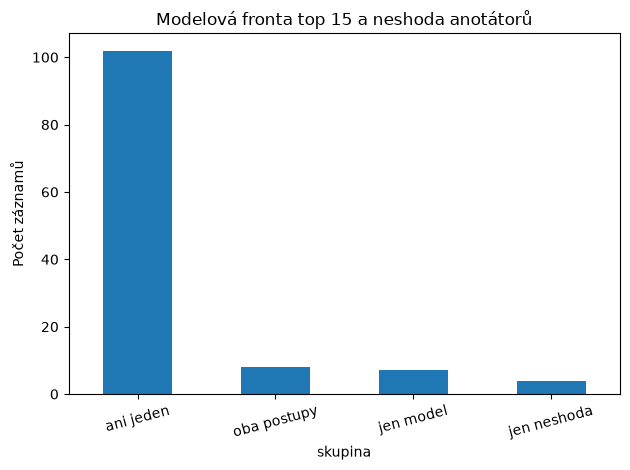

In [22]:
# P má pořadí seed × model, proto pro model vybíráme každý druhý běh.
k=min(15,len(model_data))
poradi_modelu={}
for j,name in enumerate(modely):
    tab=model_data[['zaznam_id','objekt_id','label']].copy()
    tab['skore_k_provereni']=1-np.median(p_obs[j::len(modely)],axis=0)
    tab=tab.sort_values(['skore_k_provereni','zaznam_id'],ascending=[False,True])
    poradi_modelu[name]=tab
    print(name); display(tab.head(k))
    tab.to_csv(VYSTUP/f'poradi_{name}.csv',index=False)
poradi_modelu['spolecna']=diagnostika
prekryvy=[]
for x,yname in combinations(poradi_modelu,2):
    a=set(poradi_modelu[x].head(k).zaznam_id); b=set(poradi_modelu[yname].head(k).zaznam_id)
    prekryvy.append({'poradi_1':x,'poradi_2':yname,'k':k,'spolecnych':len(a&b),'podil_z_k':len(a&b)/k,'Jaccard':len(a&b)/len(a|b)})
display(pd.DataFrame(prekryvy))
model_ids=set(diagnostika.head(k).zaznam_id)
neshoda_ids=set(konfliktni_id)
prehled_metod=objekty[['zaznam_id','objekt_id']].copy()
prehled_metod['model']=prehled_metod.zaznam_id.isin(model_ids)
prehled_metod['neshoda']=prehled_metod.zaznam_id.isin(neshoda_ids)
prehled_metod['skupina']=np.select([prehled_metod.model & prehled_metod.neshoda,prehled_metod.model,prehled_metod.neshoda],
                                 ['oba postupy','jen model','jen neshoda'],default='ani jeden')
display(prehled_metod.skupina.value_counts())
for skupina in ['oba postupy','jen model','jen neshoda']:
    print(skupina)
    display(prehled_metod.loc[prehled_metod.skupina.eq(skupina)].merge(anotace_siroka,on='zaznam_id',how='left'))
prehled_metod.to_csv(VYSTUP/'porovnani_model_neshoda.csv',index=False)
ax=prehled_metod.skupina.value_counts().plot.bar(ylabel='Počet záznamů',title=f'Modelová fronta top {k} a neshoda anotátorů')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 10. Následné vyhodnocení syntetického experimentu
Teprve po sestavení a exportu pořadí otevřeme učitelskou referenci. `precision@k` vyjadřuje podíl skutečně změněných labelů A ve frontě, nikoli klasifikační přesnost. Výběr k ani modelů podle této reference zpětně neupravujeme. Fronta revizí ponechává nové labely prázdné a čeká na člověka.

In [23]:
fronta_k_revizi = diagnostika.head(15).copy()
fronta_k_revizi["rozhodnuti"] = "ceka_na_kontrolu"
fronta_k_revizi["novy_label"] = pd.NA
fronta_k_revizi["duvod_rozhodnuti"] = pd.NA
fronta_k_revizi["kontroloval"] = pd.NA
fronta_k_revizi["cas_kontroly"] = pd.NA
fronta_k_revizi.to_csv(VYSTUP / "fronta_k_revizi.csv", index=False)

# Až nyní otevřeme učitelskou referenci, abychom zhodnotili syntetický experiment.
# V reálném datasetu taková spolehlivá reference obvykle není k dispozici.
reference_labelu = pd.read_csv(DATA / "reference_labelu_pro_vyucujiciho.csv")
vyhodnoceni = diagnostika.merge(reference_labelu, on="zaznam_id", validate="one_to_one")
vyhodnoceni["zmeneny_label_v_simulaci"] = vyhodnoceni["label"] != vyhodnoceni["label_generatoru"]
k = 15
print("Změněných labelů osoby A:", vyhodnoceni["zmeneny_label_v_simulaci"].sum())
print(f"Podíl skutečně změněných labelů mezi prvními {k} kandidáty:",
      vyhodnoceni.head(k)["zmeneny_label_v_simulaci"].mean())
# Toto je precision@k pro tuto syntetickou ukázku, nikoli přesnost klasifikačního modelu.

Změněných labelů osoby A: 9
Podíl skutečně změněných labelů mezi prvními 15 kandidáty: 0.6


In [24]:
vysledky=[]
for name,tab in poradi_modelu.items():
    ev=tab.merge(reference_labelu,on='zaznam_id',validate='one_to_one')
    ev['chyba']=ev.label.ne(ev.label_generatoru)
    vysledky.append({'model':name,'k':k,'nalezenych_chyb':ev.head(k).chyba.sum(),
                     'precision_at_k':ev.head(k).chyba.mean(),'recall_at_k':ev.head(k).chyba.sum()/ev.chyba.sum() if ev.chyba.sum() else np.nan})
display(pd.DataFrame(vysledky))
assert otisky == {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in DATA.glob('*.csv')}
print('Ověřeno: všechna zdrojová CSV jsou beze změny.')

Ověřeno: všechna zdrojová CSV jsou beze změny.


,model,k,nalezenych_chyb,precision_at_k,recall_at_k
0,logisticka_regrese,15,9,0.6,1.0
1,nahodny_les,15,9,0.6,1.0
2,spolecna,15,9,0.6,1.0


## 11. Návrh diagnostiky regresního targetu
1. Nejprve ověřit jednotky, rozsah významu targetu, časovou návaznost a klíč při spojení objektů. Záměna kg/g či °C/°F může vysvětlit nesoulad bez chyby modelu.
2. Vytvořit opakované OOF predikce alespoň lineárního a stromového modelu. Opakované objekty držet v jedné skupině; časová data dělit podle času. Transformace učit výhradně na trénovací části.
3. Pro každý záznam evidovat znaménkové reziduum `y − predikce`, absolutní reziduum a jeho medián i rozptyl napříč opakováními a modely. Zohlednit různou přirozenou nejistotu skupin; samotné velké reziduum nemusí znamenat chybu targetu.
4. Kandidáty k ruční kontrole prioritizovat podle stabilního nesouladu více modelů. Kontrolovat původní protokol, jednotky, desetinný oddělovač a záměnu objektů; porovnat opakovaná měření stejného objektu. Zároveň prověřit nedostatečné příznaky a systematické selhání modelů.
5. Změnu smí potvrdit člověk na základě zdrojových podkladů. Audit obsahuje původní target, navrženou hodnotu, důkaz, kontrolujícího a čas. Bez důkazu target zachovat. Teprve po uzavření kontroly znovu vyhodnotit na nezávislých datech.

Jde o návrh postupu; v tomto cvičení neprovádíme detekci odlehlých hodnot ani automatické přepisování targetů.

## 12. Interpretace dosažených výsledků

- U stanice S02 dne 1. 1. 2026 v 08:00 vybere původní pořadí teplotu 6,9 °C; sestupné řazení aktualizace správně ponechá opravenou verzi 7,5 °C z 8. 1. 2026.
- Rozdíl agregací je patrný například u S02 v únoru: přímý průměr je 6,0833 °C, průměr denních průměrů 6,3571 °C. Denní četnost kolísá mezi jedním a dvěma provozními měřeními. U skupin se dvěma měřeními každý den se oba postupy shodují.
- Jedna substituce v názvu Most sníží skóre na 75 %, zatímco v dlouhém názvu na 96,67 %. Stejný práh 85 % tak rozhodne rozdílně. Přidaná téměř shodná reference sníží odstup pro „Teplice centurm“ z 33,33 na 13,33 bodu a změní nejlepšího kandidáta; samotné vysoké skóre nemůže zaručit věcnou správnost.
- Pořadí logistické regrese a lesa sdílejí 10 z prvních 15 kandidátů. Společná diagnostika sdílí s regresí 13 a s lesem 12 kandidátů. Modelová fronta a neshoda anotátorů se překrývají v 8 případech; 7 zachytí jen model a 4 jen neshoda. Postupy se doplňují.
- Následná učitelská reference potvrzuje v každé frontě 9 skutečně změněných labelů z 15: precision@15 = 60 % a recall@15 = 100 % v tomto malém syntetickém experimentu. Šest dalších kandidátů nemá změněný label generátoru, což názorně ukazuje, proč modelové podezření není důkaz chyby.
